In [1]:
!pip install -q langchain langchain-groq

In [2]:
import os
from google.colab import userdata
os.environ["GROQ_API_KEY"] = userdata.get("GROK_API_KEY")   # LangChain reads it from here

from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.3)

In [4]:
from typing import Literal
from pydantic import BaseModel, Field

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description=(
            "order = wants to place a vegetable pickup request; "
            "faq = asks about vegetable prices, shop hours, or pickup policy; "
            "other = anything else"
        )
    )

classifier = llm.with_structured_output(Intent)

def handle(message: str) -> str:
    intent = classifier.invoke(message).intent

    if intent == "order":
        return take_order(message)
    elif intent == "faq":
        return answer_faq(message)
    else:
        return "I can help with vegetable prices, shop hours, and pickup orders. What would you like?"

In [5]:
from typing_extensions import TypedDict

class FreshBasketState(TypedDict):
    message: str  # What the customer wrote
    intent: str   # Filled in by the classification step
    reply: str    # Filled in by the order, FAQ, or fallback path

In [6]:
from langgraph.graph import StateGraph, START, END


def classify(state: FreshBasketState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}


def answer_faq(state: FreshBasketState) -> dict:
    response = llm.invoke([
        (
            "system",
            "You are the FAQ assistant for Fresh Basket Vegetable Shop. "
            "Customers can request in-store pickup. The shop confirms stock "
            "and pickup details. Delivery availability must be checked with the shop.",
        ),
        ("human", state["message"]),
    ])
    return {"reply": response.text}


builder = StateGraph(FreshBasketState)
builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)

# This example sends every message to the FAQ node after classification.
builder.add_edge(START, "classify")
builder.add_edge("classify", "faq")
builder.add_edge("faq", END)

graph = builder.compile()

result = graph.invoke({"message": "Can I collect my vegetables from the shop?"})
print(result["reply"])

**Yes – you can collect your vegetables directly from Fresh Basket!**  

Here’s how it works:

1. **Place your order** (online, by phone, or in‑person).  
2. **Tell us you’d like “in‑store pickup.”**  
3. **We’ll check stock** for the items you’ve selected and confirm they’re available.  
4. **We’ll send you a pickup confirmation** with:  
   * The exact **date and time window** you can swing by.  
   * Our **store address** and any parking instructions.  
   * A **pickup code or QR‑code** (if you’re using the app) to speed up the hand‑off.  

**What to bring:**  
* Your order confirmation (email, app screen, or order number).  
* A valid ID (if required by the store).  

If you need the vegetables delivered instead, just let us know and we’ll check delivery availability for your address.

Feel free to share the items you’d like or the order number, and we’ll lock in your pickup details right away!


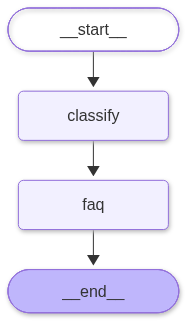

{'classify': {'intent': 'faq'}}
{'faq': {'reply': 'Yes—you can collect your vegetables from the shop using our in‑store pickup service.  \nWe’ll just need to confirm that the items you want are in stock and arrange the exact pickup time and location with you. If you let us know what you’d like, we’ll get those details confirmed for you.'}}


In [10]:
from IPython.display import Image, display

# Display the Fresh Basket workflow in Colab.
display(Image(graph.get_graph().draw_mermaid_png()))

# Print each node's update as the graph runs.
for step in graph.stream(
    {"message": "Can I collect my vegetables from the shop?"},
    stream_mode="updates",
):
    print(step)

In [11]:
!pip install -q langgraph

In [13]:
from google.colab import userdata
from langchain_groq import ChatGroq

# Enable Notebook access for GROQ_API_KEY in Colab Secrets.
api_key = userdata.get("GROK_API_KEY").strip()

if not api_key:
    raise ValueError("GROQ_API_KEY is empty in Colab Secrets.")

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    api_key=api_key,
    temperature=0,
)

In [14]:
from typing import Literal

from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langchain.agents import create_agent
from langchain_core.runnables import RunnableLambda


class FreshBasketState(TypedDict):
    message: str
    intent: str
    reply: str


class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description=(
            "order = wants to place a vegetable pickup request; "
            "faq = asks about prices, shop hours, or pickup policy; "
            "other = greeting or unrelated message"
        )
    )


def classify_intent(message: str) -> Intent:
    # Use a plain-text reply to avoid Groq's forced tool-call error.
    response = llm.invoke([
        (
            "system",
            "Classify messages for Fresh Basket Vegetable Shop. "
            "Use 'order' for requests to buy vegetables or arrange pickup, "
            "'faq' for questions about prices, hours, or pickup policy, "
            "and 'other' for greetings or unrelated messages. "
            "For example, 'Can I collect my vegetables from the shop?' is 'faq'. "
            "Reply with exactly one label. Do not answer the question.",
        ),
        ("human", message),
    ])

    label = response.text.strip().lower()
    if label not in {"order", "faq", "other"}:
        return Intent(intent="other")

    return Intent(intent=label)


classifier = RunnableLambda(classify_intent)

In [27]:
FAQ_PROMPT = """You answer questions for Fresh Basket Vegetable Shop.
Use get_price for prices and is_open for shop hours. Convert grams to kilograms
before checking prices. Customers can request in-store pickup.
If a detail is missing, say "I'll check with the shop." Keep replies under 50 words."""

ORDER_PROMPT = """You take pickup requests for Fresh Basket Vegetable Shop.
Use get_price for totals. Convert grams to kilograms before calling tools.
Collect the customer's name, vegetable, weight in kilograms, and pickup date.
Ask for missing details, then summarize the request and get explicit confirmation
before calling log_order. After saving, repeat the details and explain that the
shop will confirm pickup. Keep replies under 60 words."""

faq_agent = create_agent(model=llm, tools=[get_price, is_open], system_prompt=FAQ_PROMPT)
order_agent = create_agent(model=llm, tools=[get_price, log_order], system_prompt=ORDER_PROMPT)

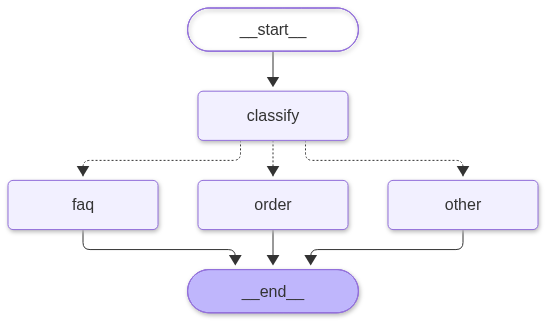

In [28]:
from IPython.display import Image, display


def classify(state: FreshBasketState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}


def ask_agent(agent, message: str) -> str:
    result = agent.invoke({"messages": [{"role": "user", "content": message}]})
    return result["messages"][-1].text


def answer_faq(state: FreshBasketState) -> dict:
    return {"reply": ask_agent(faq_agent, state["message"])}


def take_order(state: FreshBasketState) -> dict:
    return {"reply": ask_agent(order_agent, state["message"])}


def other(state: FreshBasketState) -> dict:
    return {
        "reply": "Hello from Fresh Basket! I can help with vegetable prices, shop hours, and pickup requests."
    }


def route(state: FreshBasketState) -> str:
    return state["intent"]


builder = StateGraph(FreshBasketState)
builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_node("order", take_order)
builder.add_node("other", other)

builder.add_edge(START, "classify")
builder.add_conditional_edges(
    "classify",
    route,
    {"order": "order", "faq": "faq", "other": "other"},
)
builder.add_edge("faq", END)
builder.add_edge("order", END)
builder.add_edge("other", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [29]:
tests = [
    "Do you deliver to my area?",
    "I'm Jenny. I'd like to pick up 500 g of carrots on 24 Dec.",
    "Good morning!",
    "How much does 1 kg of tomatoes cost?",
]

for msg in tests:
    print("\nCustomer:", msg)
    for step in graph.stream({"message": msg}, stream_mode="updates"):
        print("  ", step)


Customer: Do you deliver to my area?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': "I'll check with the shop."}}

Customer: I'm Jenny. I'd like to pick up 500 g of carrots on 24 Dec.
   {'classify': {'intent': 'order'}}
   {'order': {'reply': 'Jenny, you’d like 0.5\u202fkg of carrots for ₹30, to pick up on 24\u202fDec. Shall I confirm this order?'}}

Customer: Good morning!
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Hello from Fresh Basket! I can help with vegetable prices, shop hours, and pickup requests.'}}

Customer: How much does 1 kg of tomatoes cost?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': '1\u202fkg of tomatoes costs ₹40.00. You can pick it up in‑store.'}}
